In [878]:
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import STL
import seaborn as sns
import numpy as np
from datetime import timedelta
from sklearn.preprocessing import LabelEncoder
import category_encoders as ce
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,root_mean_squared_error
import xgboost as xgb
from sklearn.preprocessing import StandardScaler

In [879]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
file_path = 'routes_with_total_distances.csv'
df = pd.read_csv(file_path)

In [880]:
# Convert date columns to datetime
df['BOOKED_DATE'] = pd.to_datetime(df['BOOKED_DATE'])
df = df.sort_values(by='BOOKED_DATE')
df['DEP_DATE'] = pd.to_datetime(df['DEP_DATE'])
df['DES_DATE'] = pd.to_datetime(df['DES_DATE'])

# Ensure numeric columns are correctly typed
numeric_columns = ['ADULT', 'CHILD', 'INFANT', 'COST', 'PRICE', 'DAYS_IN_BETWEEN']
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

# Standardize text columns
text_columns = ['AIRLINE', 'BOOKING_CLASS', 'CABIN_CLASS', 'FARE_TYPE']
df[text_columns] = df[text_columns].apply(lambda x: x.str.strip().str.upper())


In [881]:
# Sample data (if necessary)
df['TOTAL_PASSENGERS'] = df['ADULT'] + df['CHILD'] + df['INFANT']
df['PER_HEAD_COST'] = df['COST'] / df['TOTAL_PASSENGERS']
df = df[df['FARE_TYPE'] == 'ITX']
df = df[df['CABIN_CLASS'] == 'ECONOMY']
# df = df[df['TOTAL_PASSENGERS'] == 1]
# df = df[df['ADULT'] == 1]

In [882]:
df['PER_HEAD_COST'].replace([np.inf, -np.inf], np.nan, inplace=True)
df['PER_HEAD_COST'].fillna(0, inplace=True)

In [883]:
def count_transits(route, dep, des):
    airports = route.split(' -> ')
    # Exclude the first (DEP) and last (DES) airports
    transits = airports[1:-1]
    # If it's a return flight, exclude the DEP airport if it appears as the last airport
    if airports[-1] == dep:
        transits = airports[1:-2]
    return len(transits)

df['TRANSITS'] = df.apply(lambda row: count_transits(row['ROUTE'], row['DEP'], row['DES']), axis=1)


In [884]:
# Group by the specified columns and count occurrences
combination_counts = df.groupby(['ROUTE', 'AIRLINE', 'BOOKING_CLASS']).size()

# Get the top 5 most frequent combinations
top_5_combinations = combination_counts.nlargest(5).reset_index(name='Count')

print(top_5_combinations)

                             ROUTE AIRLINE BOOKING_CLASS  Count
0  LHR -> CMB -> MLE -> CMB -> LHR      UL             L  13353
1  LHR -> DXB -> MLE -> DXB -> LHR      EK             T  11779
2  LHR -> DOH -> MLE -> DOH -> LHR      QR             O   9206
3  MAN -> DXB -> MLE -> DXB -> MAN      EK             T   9013
4                LGW -> ANU -> LGW      BA             O   7582


In [885]:
df = df[df['ROUTE'] == 'LHR -> CMB -> MLE -> CMB -> LHR']
df = df[df['AIRLINE'] == 'UL']
# df = df[df['BOOKING_CLASS'] == 'L']
df.shape

(33515, 43)

In [886]:
df.head().T

,1331,1332,2762,3760,3761
BOOKING_ID,11347,11347,12403,13035,13035
ITEM_NO,1.0,2.0,1.0,3.0,4.0
DEP,LHR,LHR,LHR,LHR,LHR
DES,CMB,CMB,CMB,CMB,CMB
DES_DATE,2020-02-17 00:00:00,2020-02-17 00:00:00,2020-02-29 00:00:00,2020-02-05 00:00:00,2020-02-05 00:00:00
BOOKING_STATUS,1000.0,1000.0,1000.0,1000.0,1000.0
OPTION_STATUS,600.0,600.0,200.0,200.0,200.0
BOOKING_ITEM_STATUS,1000.0,6000.0,6000.0,6000.0,6000.0
BOOKED_DATE,2019-06-23 00:00:00,2019-06-23 00:00:00,2019-07-15 00:00:00,2019-07-23 00:00:00,2019-07-23 00:00:00
FROM_DATE,2020-02-16,2020-02-16,2020-02-28,2020-02-04,2020-02-04


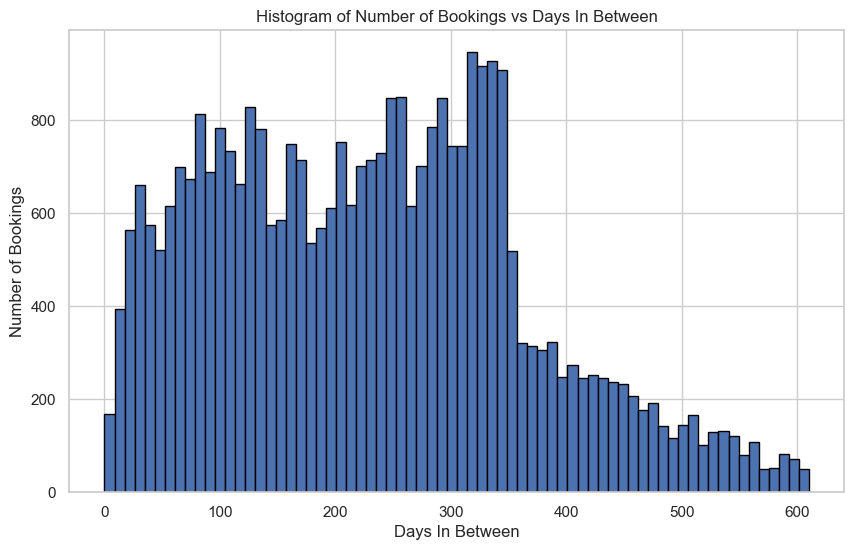

In [887]:
num_bins = 70  # Adjust this to your preference

# Determine the min and max of DAYS_IN_BETWEEN
min_days = df['DAYS_IN_BETWEEN'].min()
max_days = df['DAYS_IN_BETWEEN'].max()

# Create bins with equal width based on the range of DAYS_IN_BETWEEN
bins = np.linspace(min_days, max_days, num_bins + 1)

# Create a histogram to count the number of bookings in each bin
plt.figure(figsize=(10, 6))
plt.hist(df['DAYS_IN_BETWEEN'], bins=bins, edgecolor='black')

# Set labels and title
plt.xlabel('Days In Between')
plt.ylabel('Number of Bookings')
plt.title('Histogram of Number of Bookings vs Days In Between')

# Show the plot
plt.show()

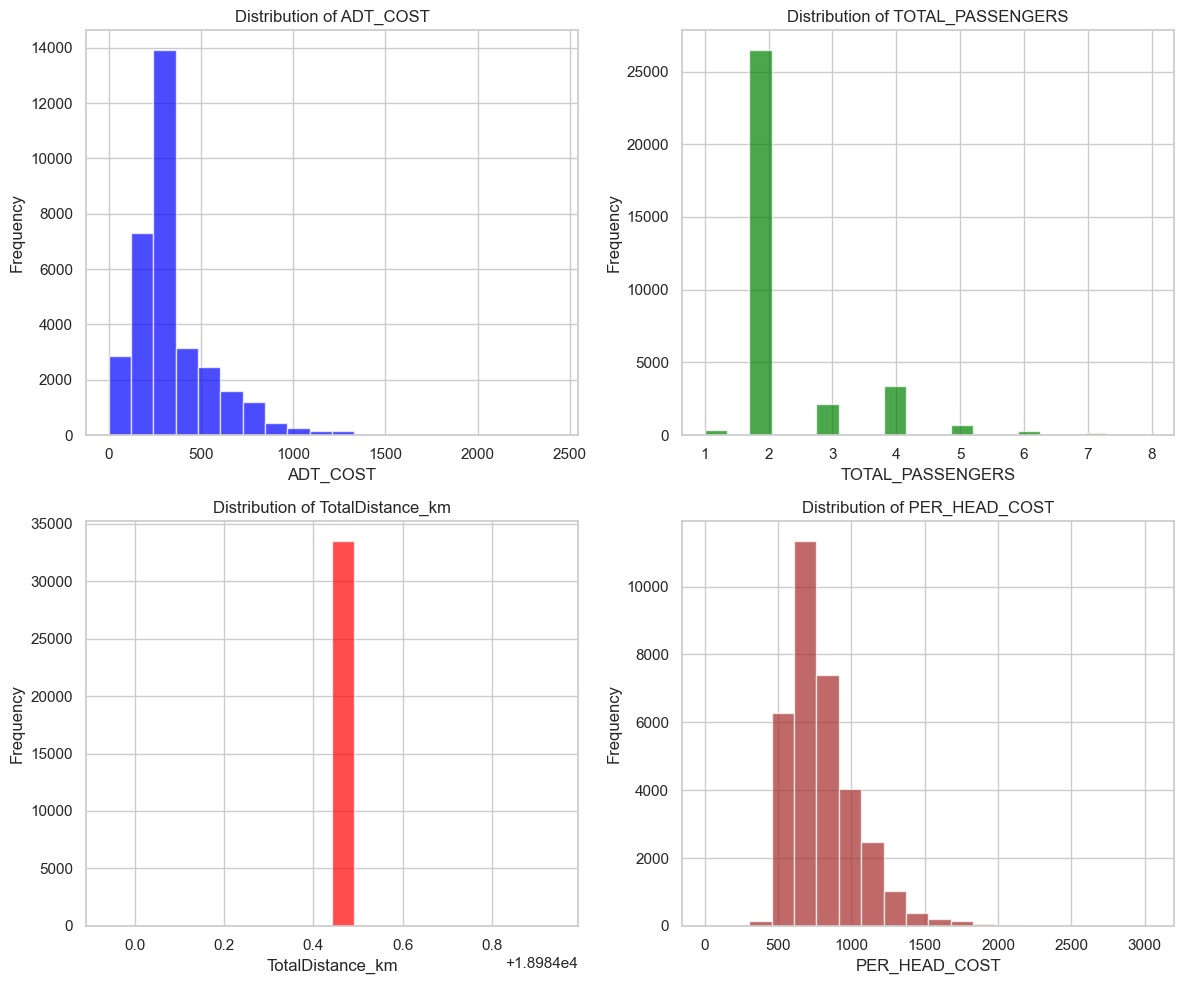

In [888]:
# Removing the 'DAYS_IN_BETWEEN' distribution and adjusting the plotting layout
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Distribution of COST
axs[0, 0].hist(df['ADT_COST'], bins=20, color='blue', alpha=0.7)
axs[0, 0].set_title('Distribution of ADT_COST')
axs[0, 0].set_xlabel('ADT_COST')
axs[0, 0].set_ylabel('Frequency')

# Distribution of PRICE
axs[0, 1].hist(df['TOTAL_PASSENGERS'], bins=20, color='green', alpha=0.7)
axs[0, 1].set_title('Distribution of TOTAL_PASSENGERS')
axs[0, 1].set_xlabel('TOTAL_PASSENGERS')
axs[0, 1].set_ylabel('Frequency')

# Distribution of TotalDistance_km
axs[1, 0].hist(df['TotalDistance_km'], bins=20, color='red', alpha=0.7)
axs[1, 0].set_title('Distribution of TotalDistance_km')
axs[1, 0].set_xlabel('TotalDistance_km')
axs[1, 0].set_ylabel('Frequency')

# Distribution of PER_HEAD_COST
axs[1, 1].hist(df['PER_HEAD_COST'], bins=20, color='brown', alpha=0.7)
axs[1, 1].set_title('Distribution of PER_HEAD_COST')
axs[1, 1].set_xlabel('PER_HEAD_COST')
axs[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


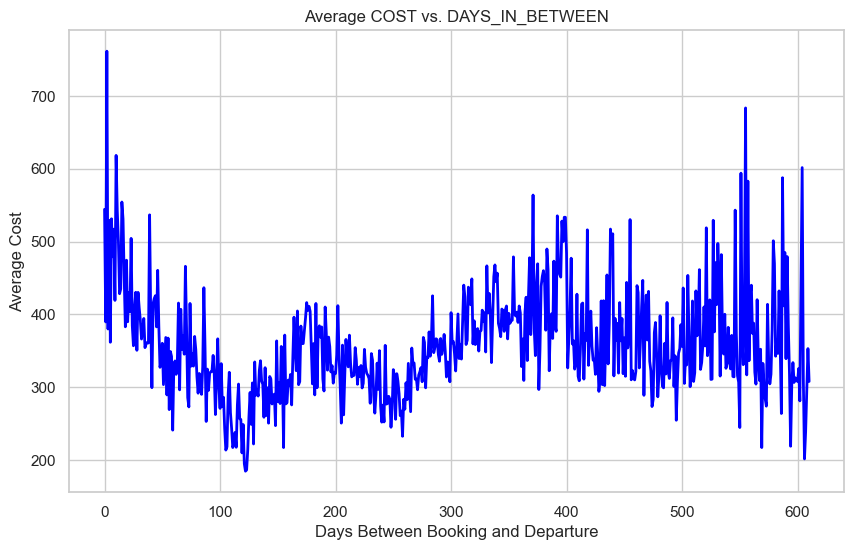

In [889]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot aesthetics using seaborn
sns.set(style="whitegrid")

# 1. Inspect the Distribution of COST vs. DAYS_IN_BETWEEN
plt.figure(figsize=(10, 6))

# Calculate the average cost per day
avg_cost_per_day = df.groupby('DAYS_IN_BETWEEN')['ADT_COST'].mean()

# Plot the average COST against DAYS_IN_BETWEEN
plt.plot(avg_cost_per_day.index, avg_cost_per_day.values, color='blue', lw=2)
plt.title('Average COST vs. DAYS_IN_BETWEEN')
plt.xlabel('Days Between Booking and Departure')
plt.ylabel('Average Cost')
plt.grid(True)
plt.show()


In [890]:
import numpy as np

# 1. Determine Bin Ranges
quantiles = df['DAYS_IN_BETWEEN'].quantile(np.arange(0, 1.1, 0.1))
print("Quantiles for DAYS_IN_BETWEEN:")
print(quantiles)

Quantiles for DAYS_IN_BETWEEN:
0.0      0.0
0.1     59.0
0.2     99.0
0.3    138.0
0.4    184.0
0.5    229.0
0.6    267.0
0.7    305.0
0.8    338.0
0.9    409.0
1.0    610.0
Name: DAYS_IN_BETWEEN, dtype: float64


In [891]:
# 1. Create the custom bins using the quantiles for training data
number_of_bins = 10

# Automatically divide into equal-frequency bins for training data
df['DAYS_BINNED'] = pd.qcut(df['DAYS_IN_BETWEEN'], q=number_of_bins, labels=False)

# Get the bin edges and labels for the training data
bin_edges = pd.qcut(df['DAYS_IN_BETWEEN'], q=number_of_bins, retbins=True)[1]
labels = [f'{int(bin_edges[i])}-{int(bin_edges[i+1]-1)}' for i in range(len(bin_edges)-1)]

# Assign these labels back to the training data
df['DAYS_BINNED_LABEL'] = pd.qcut(df['DAYS_IN_BETWEEN'], q=number_of_bins, labels=labels)

In [892]:
print(bin_edges)

[  0.  59.  99. 138. 184. 229. 267. 305. 338. 409. 610.]


In [893]:
print(labels)

['0-58', '59-98', '99-137', '138-183', '184-228', '229-266', '267-304', '305-337', '338-408', '409-609']


In [894]:
bin_counts = df['DAYS_BINNED'].value_counts().sort_index()
print("Booking counts in each bin:")
print(bin_counts)

Booking counts in each bin:
DAYS_BINNED
0    3411
1    3299
2    3372
3    3365
4    3369
5    3330
6    3363
7    3330
8    3340
9    3336
Name: count, dtype: int64


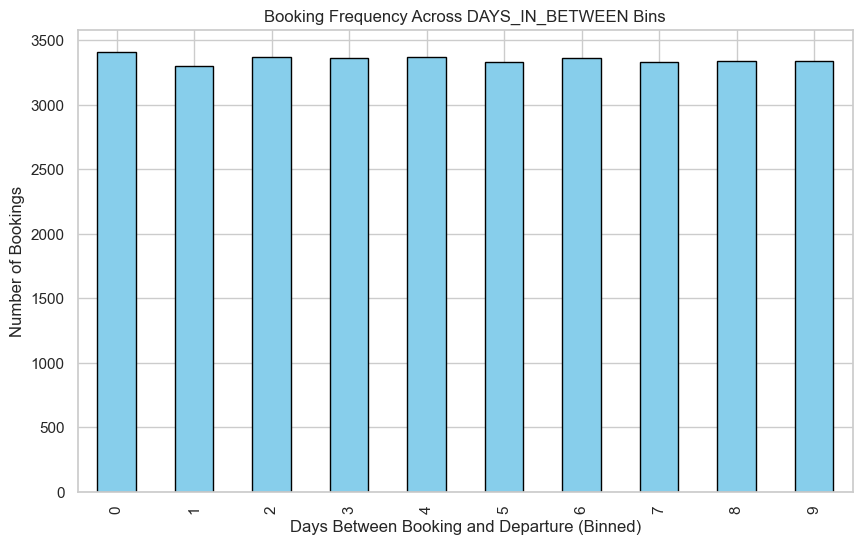

In [895]:
# 4. Visualize the distribution of bookings across bins
plt.figure(figsize=(10, 6))
bin_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Booking Frequency Across DAYS_IN_BETWEEN Bins')
plt.xlabel('Days Between Booking and Departure (Binned)')
plt.ylabel('Number of Bookings')
plt.grid(True)
plt.show()

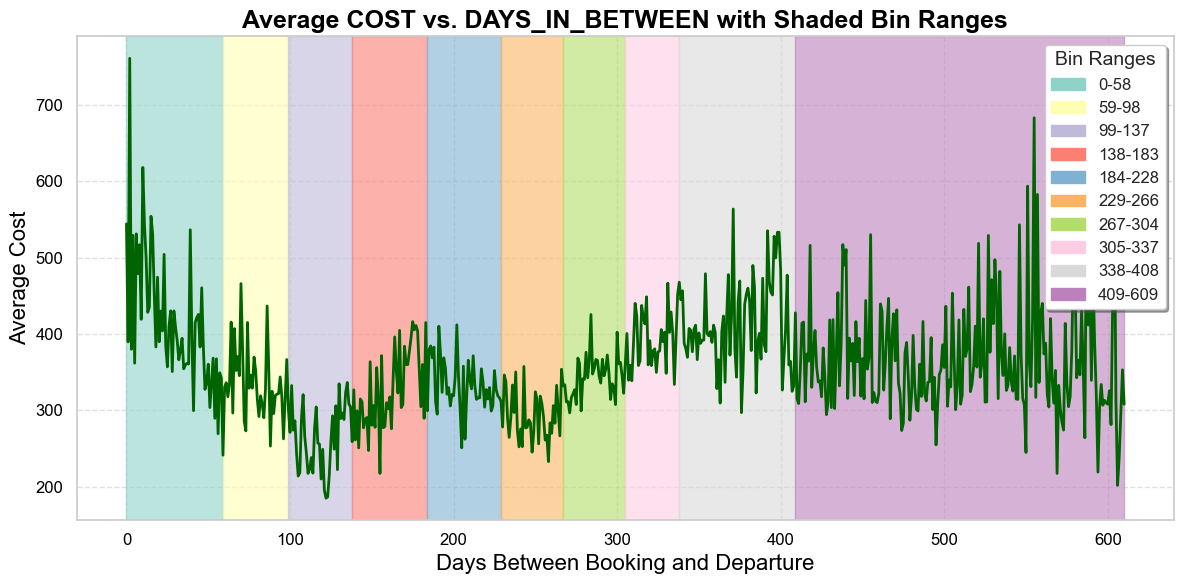

In [896]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

# Set up the plot aesthetics using seaborn
sns.set(style="whitegrid")

# 3. Plot COST vs. DAYS_IN_BETWEEN with Shaded Bins
plt.figure(figsize=(12, 6))

# Plotting the average cost per day as a line chart
plt.plot(avg_cost_per_day.index, avg_cost_per_day.values, color='darkgreen', lw=2, label='Average Cost')

# Shade the areas corresponding to the bin ranges
colors = sns.color_palette("Set3", len(bin_edges) - 1)
for i in range(len(bin_edges) - 1):
    plt.axvspan(bin_edges[i], bin_edges[i+1], color=colors[i], alpha=0.6)  # Use bin_edges for shading


# Add titles and labels with improved font settings
plt.title('Average COST vs. DAYS_IN_BETWEEN with Shaded Bin Ranges', fontsize=18, fontweight='bold', color='black')
plt.xlabel('Days Between Booking and Departure', fontsize=16, color='black')
plt.ylabel('Average Cost', fontsize=16, color='black')

# Improve the tick labels
plt.xticks(fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')

# Manually create legend patches for the shaded areas
legend_patches = [mpatches.Patch(color=colors[i], label=labels[i]) for i in range(len(labels))]

# Add the custom legend with better placement and appearance
plt.legend(handles=legend_patches, title="Bin Ranges", title_fontsize='14', fontsize='12', loc='upper right', frameon=True, shadow=True)

# Add enhanced grid lines for better readability
plt.grid(True, linestyle='--', alpha=0.6)

# Tweak layout for better spacing
plt.tight_layout()

# Show the plot
plt.show()


In [897]:
# Calculate the average cost per bin
avg_cost_per_bin = df.groupby('DAYS_BINNED')['ADT_COST'].mean()

# Display the result
avg_cost_per_bin

DAYS_BINNED
0    397.890868
1    333.166732
2    263.082888
3    327.319287
4    333.620421
5    291.355465
6    343.690675
7    394.586282
8    409.582147
9    367.686406
Name: ADT_COST, dtype: float64

In [898]:
# Calculate the overall average cost
overall_avg_cost = df['ADT_COST'].mean()

# Calculate the average cost for each bin
avg_cost_per_bin = df.groupby('DAYS_BINNED')['ADT_COST'].mean()

# Replace zeros (or near-zero values) in the shifted average costs
shifted_avg_cost_per_bin = avg_cost_per_bin.shift(1).replace(0, np.nan)

# Calculate the rate of change in cost from one bin to the next
rate_of_change_per_bin = avg_cost_per_bin.diff() / shifted_avg_cost_per_bin

# Display the rate of change for each bin
rate_of_change_per_bin


DAYS_BINNED
0         NaN
1   -0.162668
2   -0.210357
3    0.244168
4    0.019251
5   -0.126686
6    0.179627
7    0.148086
8    0.038004
9   -0.102289
Name: ADT_COST, dtype: float64

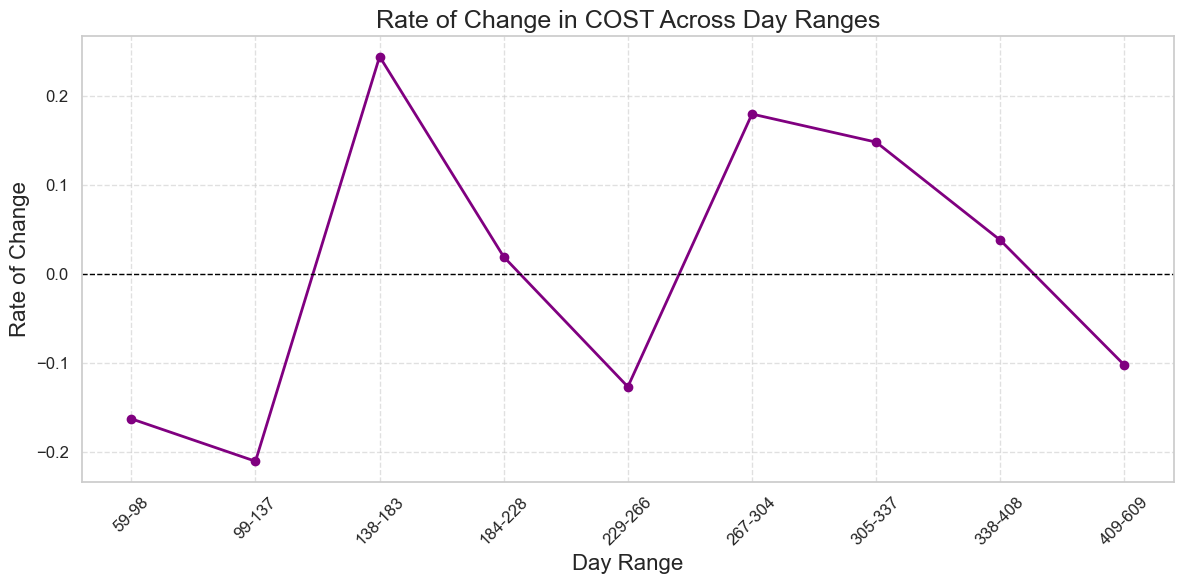

In [899]:
# Example data from the user

# Plotting Day Range vs Rate of Change
plt.figure(figsize=(12, 6))
plt.plot(labels, rate_of_change_per_bin, marker='o', linestyle='-', color='purple', lw=2)

# Add titles and labels
plt.title('Rate of Change in COST Across Day Ranges', fontsize=18)
plt.xlabel('Day Range', fontsize=16)
plt.ylabel('Rate of Change', fontsize=16)

# Highlight significant changes (positive and negative)
plt.axhline(y=0, color='black', linestyle='--', lw=1)  # Reference line at 0

# Improve the tick labels
plt.xticks(fontsize=12, rotation=45)  # Rotate labels for better readability
plt.yticks(fontsize=12)

# Enhance grid lines for better readability
plt.grid(True, linestyle='--', alpha=0.6)

# Tweak layout for better spacing
plt.tight_layout()

# Show the plot
plt.show()


In [900]:
# Replace inf and NaN values with 0 or another appropriate value
rate_of_change_per_bin.replace([np.inf, -np.inf], np.nan, inplace=True)
rate_of_change_per_bin.fillna(0, inplace=True)

# Map the multiplier to the original dataframe
df['COST_MULTIPLIER'] = pd.to_numeric(df['DAYS_BINNED'].map(rate_of_change_per_bin), errors='coerce')
# Drop rows where 'PER_HEAD_COST' is zero
df = df[df['COST_MULTIPLIER'] != 0]


In [901]:
df['BOOKED_MONTH'] = df['BOOKED_DATE'].dt.month
df['BOOKED_DAY'] = df['BOOKED_DATE'].dt.day
df['BOOKED_MONTHDAY'] = df['BOOKED_MONTH'].astype(str) + '-' + df['BOOKED_DAY'].astype(str)
df['DEP_MONTH'] = df['DEP_DATE'].dt.month
df['DEP_DAY'] = df['DEP_DATE'].dt.day
df['DEP_MONTHDAY'] = df['DEP_MONTH'].astype(str) + '-' + df['DEP_DAY'].astype(str)
df['DES_MONTH'] = df['DES_DATE'].dt.month
df['DES_DAY'] = df['DES_DATE'].dt.day
df['DES_MONTHDAY'] = df['DES_MONTH'].astype(str) + '-' + df['DES_DAY'].astype(str)

df['DEP_DES_DAYS'] = (df['DES_DATE'] - df['DEP_DATE']).dt.days
df['DAY_OF_WEEK'] = df['DEP_DATE'].dt.dayofweek

# Convert month-day to day of the year (DOY)
df['NEW_BOOKED_DATE'] = pd.to_datetime(df['BOOKED_MONTHDAY'] + '-2020', format='%m-%d-%Y').dt.dayofyear
df['NEW_DEP_DATE'] = pd.to_datetime(df['DEP_MONTHDAY'] + '-2020', format='%m-%d-%Y').dt.dayofyear
df['NEW_DES_DATE'] = pd.to_datetime(df['DES_MONTHDAY'] + '-2020', format='%m-%d-%Y').dt.dayofyear

In [902]:
df.head().T

,1331,1332,2762,3760,3761
BOOKING_ID,11347,11347,12403,13035,13035
ITEM_NO,1.0,2.0,1.0,3.0,4.0
DEP,LHR,LHR,LHR,LHR,LHR
DES,CMB,CMB,CMB,CMB,CMB
DES_DATE,2020-02-17 00:00:00,2020-02-17 00:00:00,2020-02-29 00:00:00,2020-02-05 00:00:00,2020-02-05 00:00:00
BOOKING_STATUS,1000.0,1000.0,1000.0,1000.0,1000.0
OPTION_STATUS,600.0,600.0,200.0,200.0,200.0
BOOKING_ITEM_STATUS,1000.0,6000.0,6000.0,6000.0,6000.0
BOOKED_DATE,2019-06-23 00:00:00,2019-06-23 00:00:00,2019-07-15 00:00:00,2019-07-23 00:00:00,2019-07-23 00:00:00
FROM_DATE,2020-02-16,2020-02-16,2020-02-28,2020-02-04,2020-02-04


In [903]:
encoding_features = ['ROUTE', 'AIRLINE', 'BOOKING_CLASS', 'CABIN_CLASS', 'FARE_TYPE']

label_encoders = {}
for feature in encoding_features:
    le = LabelEncoder()
    df[feature] = le.fit_transform(df[feature])
    label_encoders[feature] = le

In [904]:
df.shape

(30104, 60)

In [905]:
# Assuming your original dataset is in a DataFrame called `df`
test_set = df.tail(500)
# Drop the last 500 rows from the original dataset
df = df.iloc[:-500]


In [906]:
df.shape

(29604, 60)

In [907]:
df.to_csv('checking.csv')

In [908]:
features = ['ADULT', 'BOOKING_CLASS', 'DAYS_IN_BETWEEN','NEW_BOOKED_DATE','NEW_DEP_DATE','NEW_DES_DATE']

target = 'ADT_COST'

train_df = df[df['BOOKED_DATE'].dt.year < 2022]
test_df = df[df['BOOKED_DATE'].dt.year >= 2022]
test_df = test_df[test_df['BOOKED_DATE'].dt.year < 2025]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

In [909]:
X_train.shape

(16334, 6)

In [910]:
X_test.shape

(13270, 6)

In [911]:
# Initialize and train the model
model = XGBRegressor()

model.fit(X_train, y_train)

# Predict on the test set
predictions = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse}')

rmse = root_mean_squared_error(y_test, predictions)
print(f'Root Mean Squared Error: {rmse}')

Mean Squared Error: 22796.709078550277
Root Mean Squared Error: 150.9857909822983


<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

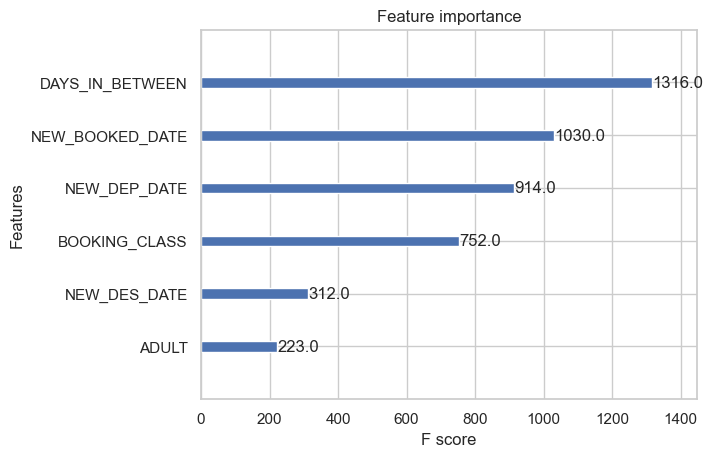

In [912]:
xgb.plot_importance(model)

In [913]:
# Prepare the test set
X_test = test_set[features]  # Replace 'target_column' with the actual target column name
y_test = test_set['ADT_COST']

# Test the model
y_pred = model.predict(X_test)

# Evaluate the model
from sklearn.metrics import mean_squared_error, r2_score

# Calculate regression metrics
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error: {rmse}')



Mean Squared Error (MSE): 27605.592446427225
Root Mean Squared Error: 166.14930769168802


In [914]:
# Assuming y_test and y_pred are the actual and predicted costs, respectively
comparison_df = pd.DataFrame({
    'Actual Cost': y_test,
    'Predicted Cost': y_pred
})

# Display the first few rows to check
print(comparison_df.head(10))


        Actual Cost  Predicted Cost
682217        495.0      172.228958
726995        944.0      891.996155
726993        944.0      891.996155
726992        944.0      891.996155
726994        944.0      891.996155
739854        535.0      520.097839
746907        565.0      443.035492
747665        420.0      188.634598
747873        550.0      289.257629
745493        917.0      456.134857


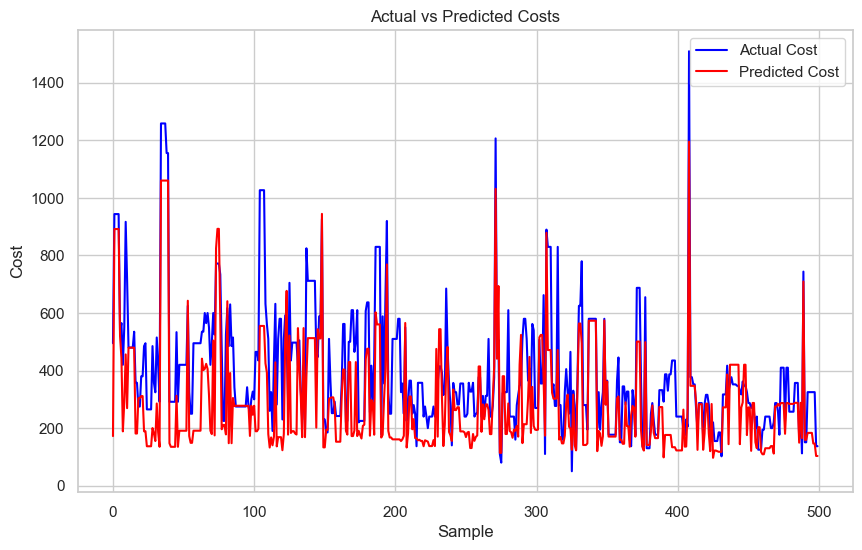

In [915]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(comparison_df['Actual Cost'].values, label='Actual Cost', color='blue')
plt.plot(comparison_df['Predicted Cost'].values, label='Predicted Cost', color='red')
plt.legend()
plt.title('Actual vs Predicted Costs')
plt.xlabel('Sample')
plt.ylabel('Cost')
plt.show()


In [916]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Create a sample dataframe
data = {
    'BOOKED_DATE': pd.to_datetime(['2024-06-09', '2024-06-09', '2024-06-09', '2024-06-09', '2024-06-09']),
    'ADULT': [1, 1, 1, 1, 1],
    'BOOKING_CLASS': ['L', 'L', 'L', 'L', 'L'],
    'DAYS_IN_BETWEEN': [468, 498, 529, 559, 590],
    'DEP_DATE': pd.to_datetime(['2025-09-20', '2025-10-20', '2025-11-20', '2025-12-20', '2026-01-20']),
    'DES_DATE': pd.to_datetime(['2025-09-29', '2025-10-29', '2025-11-29', '2025-12-29', '2026-01-29']),
}

df = pd.DataFrame(data)

# Basic date transformation logic remains the same
df['BOOKED_MONTH'] = df['BOOKED_DATE'].dt.month
df['BOOKED_DAY'] = df['BOOKED_DATE'].dt.day
df['BOOKED_MONTHDAY'] = df['BOOKED_MONTH'].astype(str) + '-' + df['BOOKED_DAY'].astype(str)
df['DEP_MONTH'] = df['DEP_DATE'].dt.month
df['DEP_DAY'] = df['DEP_DATE'].dt.day
df['DEP_MONTHDAY'] = df['DEP_MONTH'].astype(str) + '-' + df['DEP_DAY'].astype(str)
df['DES_MONTH'] = df['DES_DATE'].dt.month
df['DES_DAY'] = df['DES_DATE'].dt.day
df['DES_MONTHDAY'] = df['DES_MONTH'].astype(str) + '-' + df['DES_DAY'].astype(str)
df['NEW_BOOKED_DATE'] = pd.to_datetime(df['BOOKED_MONTHDAY'] + '-2020', format='%m-%d-%Y').dt.dayofyear
df['NEW_DEP_DATE'] = pd.to_datetime(df['DEP_MONTHDAY'] + '-2020', format='%m-%d-%Y').dt.dayofyear
df['NEW_DES_DATE'] = pd.to_datetime(df['DES_MONTHDAY'] + '-2020', format='%m-%d-%Y').dt.dayofyear
df['DAYS_IN_BETWEEN'] = (df['DEP_DATE'] - df['BOOKED_DATE']).dt.days

# Define the label ranges

bin_ranges = [(int(l.split('-')[0]), int(l.split('-')[1])) for l in labels]

# Function to find the closest bin for a given DAYS_IN_BETWEEN value
def find_closest_bin(days):
    for i, (start, end) in enumerate(bin_ranges):
        if start <= days <= end:
            return i
    return -1  # Return -1 if no bin is found

# Function to calculate the shift days based on bin ranges
def calculate_shift_days(days_in_between):
    # Find the closest bin for the given DAYS_IN_BETWEEN
    closest_bin_index = find_closest_bin(days_in_between)
    if closest_bin_index == -1:
        return 0  # No shift if no bin found

    # Get the bin range (start and end)
    bin_start, bin_end = bin_ranges[closest_bin_index]

    # Calculate the midpoint of the bin range for shifting
    target_days = (bin_start + bin_end) // 2

    # Return the shift value (target_days minus the current days in between)
    return target_days - days_in_between

# Shift BOOKED_DATE so that it falls into the correct bin range
def shift_booked_date(row):
    days_in_between = row['DAYS_IN_BETWEEN']
    closest_bin_index = find_closest_bin(days_in_between)
    
    if closest_bin_index == -1:
        return row['BOOKED_DATE']  # If no bin found, keep the original date
    
    # Get the bin start and end
    bin_start, bin_end = bin_ranges[closest_bin_index]
    
    # Calculate the midpoint of the bin range to shift the date to
    target_days = (bin_start + bin_end) // 2
    
    # Adjust the BOOKED_DATE based on the new target days
    adjusted_booked_date = row['DEP_DATE'] - timedelta(days=target_days)
    return adjusted_booked_date

# Apply the shift to BOOKED_DATE based on the closest bin
df['SHIFTED_BOOKED_DATE'] = df.apply(shift_booked_date, axis=1)

# Number of bins/windows for shifting dates
num_windows = 10

# Initialize a dataframe to store results for each window/bin
results = pd.DataFrame()

# Loop over each window/bin (0 to num_windows)
for window in range(num_windows):
    # Shift the BOOKED_DATE by an additional number of days for each window
    df['BOOKED_DATE'] = df['SHIFTED_BOOKED_DATE'] + pd.to_timedelta(window * 35, unit='D')
    
    # Recalculate DAYS_IN_BETWEEN for each shifted BOOKED_DATE
    df['DAYS_IN_BETWEEN'] = (df['DEP_DATE'] - df['BOOKED_DATE']).dt.days
    
    # Use the original feature names (as the model was trained with them)
    features = ['ADULT', 'BOOKING_CLASS', 'DAYS_IN_BETWEEN', 'NEW_BOOKED_DATE', 'NEW_DEP_DATE', 'NEW_DES_DATE']
    
    # Encoding categorical feature 'BOOKING_CLASS' (Assuming label_encoders were trained previously)
    encoding_features = ['BOOKING_CLASS']
    for feature in encoding_features:
        le = label_encoders[feature]  # Make sure label_encoders are defined based on training data
        df[feature] = df[feature].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)
    
    # Prepare the features for prediction
    X = df[features]
    
    # Predict the cost using the trained model
    df[f'Predicted_Cost_{window}'] = model.predict(X).round(0).astype(int)
    
    # Add the predicted cost to the results dataframe
    results[f'Window_{window}'] = df[f'Predicted_Cost_{window}']

# Adding the Departure and Destination Date to the results DataFrame
results['Departure Date'] = df['DEP_DATE']
results['Destination Date'] = df['DES_DATE']

# Reorder columns to have the Departure Date and Destination Date first
results = results[['Departure Date', 'Destination Date'] + [f'Window_{i}' for i in range(num_windows)]]

# Display the final results DataFrame
print(results)


  Departure Date Destination Date  Window_0  Window_1  Window_2  Window_3  \
0     2025-09-20       2025-09-29       340       789      1293       908   
1     2025-10-20       2025-10-29       363       809      1277       892   
2     2025-11-20       2025-11-29       337       823      1299       914   
3     2025-12-20       2025-12-29       198       335       811       735   
4     2026-01-20       2026-01-29       506      1074      1140      1169   

   Window_4  Window_5  Window_6  Window_7  Window_8  Window_9  
0       862       665       719       694       693       693  
1       881       696       760       738       730       759  
2       919       715       747       708       719       719  
3       735       851       880       994      1010      1049  
4      1157       967      1136       905       890       759  
